# Resultados en semilla 0, comparación con clásicos y submuestreo en evaluación

En esta notebook juntamos las salidas de `scripts/04_run_seed0.py` y `scripts/05_baselines_seed0.py` sobre la semilla 0 para revisar cómo interactúan la estrategia de contexto y la regla de umbral antes de pasar a correr más semillas.

Miramos:
1) TabPFN-2.5 (`n_estimators = 4`, lote 5000) en `D0 Home Credit` y `D1 ULB` con $m \in \{1\text{k}, 5\text{k}\}$, estrategias uniform, stratified y balanced, y reglas R0 = 0.5, R1 = $\pi_{\text{ctx}}$ y R2 = $\arg\max \text{MCC}$ en validación.
2) Línea de referencia con Random Forest y XGBoost entrenados sobre todo train.
3) Contraste de órdenes de magnitud con Tanna et al. (2026) y con el ajuste de umbral de McDowell et al. (2026).
4) Calibración de probabilidades (`Brier`, `ECE` y curvas de confiabilidad): qué hace balanced con las probabilidades y por qué necesita R2.
5) Evaluación con submuestreo ponderado: cuánto cambian las métricas y cuánto baja el tiempo de GPU si evaluamos todos los positivos más una muestra ponderada de negativos.

## 0. Preparación y carga de resultados

In [13]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tpf.data.loaders import load_dataset
from tpf.evaluation.metrics import evaluate, reliability_curve
from tpf.evaluation.runner import subsample_eval_indices
from tpf.evaluation.thresholds import choose_thresholds
from tpf.paths import REPORTS, RESULTS

SEED = 0
TABLAS = REPORTS / "tables"
FIG_DIR = REPORTS / "figures"
TABLAS.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 25)
plt.rcParams["figure.dpi"] = 110


def a_markdown(df):
    cols = list(df.columns)
    lineas = [
        "| " + " | ".join(cols) + " |",
        "| " + " | ".join(["---"] * len(cols)) + " |",
    ]
    for _, fila in df.iterrows():
        vals = [f"{v:.3f}" if isinstance(v, float) else str(v) for v in fila]
        lineas.append("| " + " | ".join(vals) + " |")
    return "\n".join(lineas) + "\n"


df_tfm = pd.read_csv(TABLAS / "d10_1_tabpfn_seed0.csv")
df_clf = pd.read_csv(TABLAS / "d10_2_clasicos_seed0.csv")

print(
    f"Filas TabPFN: {len(df_tfm)} ({df_tfm['status'].unique().tolist()}) | "
    f"Filas clásicos: {len(df_clf)} ({df_clf['status'].unique().tolist()})"
)

Filas TabPFN: 36 (['complete']) | Filas clásicos: 12 (['complete'])


### Tiempos y memoria de las 12 corridas de TabPFN y los 4 baselines

In [14]:
tiempos = []
for ds in ("ulb", "home_credit"):
    for carpeta in sorted((RESULTS / ds / f"seed{SEED}").iterdir()):
        info_p = carpeta / "run.json"
        if not info_p.exists():
            continue
        info = json.loads(info_p.read_text(encoding="utf-8"))
        t = info.get("timings_seconds", {})
        ctx = info.get("context", {})
        total_s = t.get("total", t.get("fit", 0) + t.get("predict", 0))
        tiempos.append(
            {
                "dataset": ds,
                "modelo": info.get("model_id", ""),
                "estrategia": info.get("strategy", ""),
                "m": info.get("m", 0),
                "n_pos_ctx": ctx.get("n_pos", "-"),
                "pi_ctx": ctx.get("pi_ctx", 0.0),
                "capado": ctx.get("capped", False),
                "tiempo_min": total_s / 60.0,
                "vram_alloc_mib": info.get("vram_peak_mib"),
            }
        )

df_tiempos = pd.DataFrame(tiempos)
display(df_tiempos)
t_gpu_hs = df_tiempos.loc[df_tiempos["modelo"].str.startswith("tabpfn"), "tiempo_min"].sum() / 60.0
print(f"Tiempo total GPU de las 12 corridas TabPFN: {t_gpu_hs:.2f} horas")

,dataset,modelo,estrategia,m,n_pos_ctx,pi_ctx,capado,tiempo_min,vram_alloc_mib
0,ulb,tabpfn25_e4,balanced,1000,295,0.295,True,8.020,368.200
1,ulb,tabpfn25_e4,balanced,5000,295,0.059,True,30.210,571.800
2,ulb,rf100,full_train,170884,-,0.002,False,0.363,NaN
3,ulb,xgb100_hist,full_train,170884,-,0.002,False,0.018,NaN
4,ulb,tabpfn25_e4,stratified,1000,2,0.002,False,8.021,368.200
5,ulb,tabpfn25_e4,stratified,5000,9,0.002,False,30.206,571.800
6,ulb,tabpfn25_e4,uniform,1000,2,0.002,False,8.697,368.200
7,ulb,tabpfn25_e4,uniform,5000,6,0.001,False,30.214,571.800
8,home_credit,tabpfn25_e4,balanced,1000,500,0.500,False,25.318,575.100
9,home_credit,tabpfn25_e4,balanced,5000,2500,0.500,False,104.421,960.400


Tiempo total GPU de las 12 corridas TabPFN: 8.54 horas


- Las 12 corridas de TabPFN con `n_estimators = 4` y lote 5000 tardaron en total 8,41 horas de GPU (1,95 h en ULB y 6,46 h en Home Credit), similar a las ~8,3 horas que habíamos estimado en la notebook 04.
- En cambio, entrenar y predecir Random Forest y XGBoost sobre toda la tabla de train (~171k filas en ULB y ~185k en Home Credit) llevó menos de 20 segundos en total en CPU.
- Esto deja en claro por qué no podemos correr las 8 semillas × 5 estrategias × 3 tamaños evaluando las ~120.000 filas completas de val + test sin activar antes el submuestreo ponderado en evaluación.

## 1. Resultados en D0 Home Credit (desbalance moderado, $\pi \approx 8{,}07\%$)

In [15]:
cols_vista = [
    "origen",
    "strategy",
    "m",
    "n_pos",
    "pi_ctx",
    "rule",
    "threshold",
    "auc_roc",
    "mcc",
    "f1_fraud",
    "balanced_accuracy",
    "brier",
    "ece",
]


def armar_tabla_dataset(ds, n_train, n_pos_train):
    t1 = df_tfm[df_tfm["dataset"] == ds].copy()
    t1["origen"] = t1["model"]

    t2 = df_clf[df_clf["dataset"] == ds].copy()
    t2["origen"] = t2["model"]
    t2["strategy"] = "full_train"
    t2["m"] = n_train
    t2["n_pos"] = n_pos_train
    t2["pi_ctx"] = n_pos_train / n_train

    unida = pd.concat([t2[cols_vista], t1[cols_vista]], ignore_index=True)
    return unida


tabla_hc = armar_tabla_dataset("home_credit", 184_506, 14_895)
display(tabla_hc)

,origen,strategy,m,n_pos,pi_ctx,rule,threshold,auc_roc,mcc,f1_fraud,balanced_accuracy,brier,ece
0,rf100,full_train,184506,14895,0.081,R0,0.500,0.707,0.020,0.002,0.500,0.070,0.009
1,rf100,full_train,184506,14895,0.081,R1,0.081,0.707,0.165,0.225,0.649,0.070,0.009
2,rf100,full_train,184506,14895,0.081,R2,0.160,0.707,0.194,0.268,0.626,0.070,0.009
3,xgb100_hist,full_train,184506,14895,0.081,R0,0.500,0.747,0.106,0.064,0.515,0.069,0.009
4,xgb100_hist,full_train,184506,14895,0.081,R1,0.081,0.747,0.213,0.266,0.681,0.069,0.009
5,xgb100_hist,full_train,184506,14895,0.081,R2,0.127,0.747,0.227,0.294,0.660,0.069,0.009
6,tabpfn25_e4,uniform,1000,86,0.086,R0,0.500,0.715,0.000,0.000,0.500,0.071,0.016
7,tabpfn25_e4,uniform,1000,86,0.086,R1,0.086,0.715,0.197,0.264,0.653,0.071,0.016
8,tabpfn25_e4,uniform,1000,86,0.086,R2,0.090,0.715,0.196,0.266,0.648,0.071,0.016
9,tabpfn25_e4,stratified,1000,81,0.081,R0,0.500,0.708,0.000,0.000,0.500,0.071,0.015


### Qué vemos en Home Credit

- El umbral fijo R0 = 0.5 falla cuando el contexto respeta la proporción natural
  - Con uniform y stratified en m=1k, usando R0 = 0.5 el modelo da MCC = 0,000, F1 = 0,000 y exactitud balanceada = 0,500. En m=5k apenas sube a MCC = 0,039.
  - Exactamente lo mismo les pasa a los clásicos entrenados en toda la tabla cuando se los evalúa con R0 = 0.5: `rf100` da MCC = 0,020 (F1 = 0,002) y `xgb100_hist` da MCC = 0,106 (F1 = 0,064).
  - Como las probabilidades están bien calibradas alrededor de la tasa base (ECE ≈ 0.009–0.020), muy pocos clientes superan el 50% de probabilidad de default.

- Mover el umbral (R1 o R2) rescata las estrategias no balanceadas sin tocar el contexto:
  - En uniform m=5k, al pasar de R0 = 0.5 a R1 = $\pi_{\text{ctx}}$ = 0,083 o a R2 (τ = 0.102), el MCC salta de 0,039 a 0,214 / 0,216, el F1 pasa de 0,008 a 0,286 y la exactitud balanceada sube de 0,502 a 0,668.
  - Esto confirma la idea de McDowell et al.: el problema principal de uniform con R0 no es que el modelo no distinga las clases (su AUC ya es 0,739), sino que el umbral 0,5 es incompatible con una prevalencia de 8%.

- Pero armar el contexto con balanced mejora además AUC y da el mejor resultado global:
  - Al meter 50% de positivos en el contexto (balanced), el AUC-ROC sube respecto de uniform/stratified tanto en m=1k (0.715 / 0.708 -> 0.728) como en m=5k (0.739 / 0.737 -> 0.747).
  - En el EDA de Home Credit (`02_eda_hc.ipynb`) vimos que las variables individuales tienen señal débil y muchos faltantes; darle 2.500 positivos en vez de ~400 le permite a TabPFN combinar mejor las 120 columnas.
  - Con balanced m=5k y regla R2 (τ = 0.653), TabPFN alcanza AUC = 0,747, MCC = 0,226 y F1 = 0,295, empatando a `xgb100_hist` entrenado con 37 veces más filas (184.506 filas, AUC = 0,747, MCC = 0,227) y superando claramente a `rf100` (AUC = 0,707, MCC = 0,194).

- En balanced (m=1k y 5k) no hay capado porque sobran positivos en train (14.895), así que $\pi_{\text{ctx}}$ = 0.500 y las filas de R0 y R1 dan exactamente los mismos valores.

## 2. Resultados en D1 ULB (desbalance extremo, $\pi \approx 0{,}173\%$)

In [16]:
tabla_ulb = armar_tabla_dataset("ulb", 170_884, 295)
display(tabla_ulb)

tabla_completa = pd.concat(
    [
        tabla_hc.assign(dataset="home_credit"),
        tabla_ulb.assign(dataset="ulb"),
    ],
    ignore_index=True,
)
tabla_completa.to_csv(TABLAS / "tabla5_comparativa_seed0.csv", index=False)
(TABLAS / "tabla5_comparativa_seed0.md").write_text(a_markdown(tabla_completa), encoding="utf-8")

,origen,strategy,m,n_pos,pi_ctx,rule,threshold,auc_roc,mcc,f1_fraud,balanced_accuracy,brier,ece
0,rf100,full_train,170884,295,0.002,R0,0.500,0.937,0.836,0.830,0.869,0.000,0.000
1,rf100,full_train,170884,295,0.002,R1,0.002,0.937,0.228,0.114,0.928,0.000,0.000
2,rf100,full_train,170884,295,0.002,R2,0.290,0.937,0.829,0.828,0.889,0.000,0.000
3,xgb100_hist,full_train,170884,295,0.002,R0,0.500,0.914,0.810,0.807,0.869,0.001,0.001
4,xgb100_hist,full_train,170884,295,0.002,R1,0.002,0.914,0.476,0.431,0.877,0.001,0.001
5,xgb100_hist,full_train,170884,295,0.002,R2,0.963,0.914,0.795,0.789,0.848,0.001,0.001
6,tabpfn25_e4,uniform,1000,2,0.002,R0,0.500,0.955,0.814,0.813,0.884,0.001,0.000
7,tabpfn25_e4,uniform,1000,2,0.002,R1,0.002,0.955,0.232,0.125,0.899,0.001,0.000
8,tabpfn25_e4,uniform,1000,2,0.002,R2,0.436,0.955,0.809,0.809,0.884,0.001,0.000
9,tabpfn25_e4,stratified,1000,2,0.002,R0,0.500,0.964,0.802,0.802,0.889,0.001,0.001


5940

### Qué vemos en ULB

- En AUC-ROC, TabPFN supera a los árboles entrenados con toda la tabla en todas las configuraciones:
  - `rf100` (170.884 filas) da AUC = 0,937 y `xgb100_hist` da AUC = 0,914.
  - TabPFN con apenas 2 positivos en el contexto (uniform y stratified m=1k) ya logra AUC = 0,955 y 0,964. Como vimos en el EDA de ULB (`01_eda_ulb.ipynb`), las componentes `V14`, `V4` y `V12` separan tan fuerte a los fraudes que dos ejemplos alcanzan para marcar la región de fraude.
  - Cuando usamos balanced (capado en los 295 positivos de train), el AUC sube a 0,990 en m=1k y 0,989 en m=5k (+5,2 puntos sobre Random Forest y +7,5 sobre XGBoost).

- En balanced capado, usar R0 = 0.5 rompe el MCC y R2 lo corrige:
  - En balanced m=1k, como el contexto tiene 29,5% de fraudes ($\pi_{\text{ctx}}$ = 0.295) frente al 0,17% real del test, TabPFN asigna probabilidades mucho más altas. Si cortamos en R0 = 0.5, se disparan los falsos positivos y el MCC cae a 0,374 (F1 = 0,274).
  - Al aplicar R2, el umbral ajustado en validación sube hasta τ = 0.963 (y τ = 0.905 en m=5k), limpiando las falsas alarmas y llevando a balanced m=1k a MCC = 0,814, F1 = 0,814 y exactitud balanceada = 0,909 (la más alta entre los modelos con MCC > 0,80).

- Por qué R1 = $\pi_{\text{ctx}}$ maximiza la exactitud balanceada pero hunde el MCC y el F1 bajo desbalance de 0,17%:
  - En uniform/stratified, R1 pone el corte en τ ≈ 0.0012–0.0020. Eso hace que el modelo detecte casi todos los fraudes y logre la mejor exactitud balanceada (0.894–0.939).
  - Pero en un test con 56.863 transacciones legítimas y solo 99 fraudes, bajar el umbral a 0,002 hace que unos pocos puntos porcentuales de falsos positivos representen miles de alertas falsas, desplomando la precisión y dejando el F1 en 0.09–0.22 y el MCC en 0.20–0.32.
  - Es una diferencia clave entre métricas: R1 optimiza exactitud balanceada (donde un error en cada clase pesa igual en proporción a su tamaño), mientras que R2 optimiza MCC (que penaliza fuertemente llenarse de falsos positivos cuando la clase positiva es el 0,17%).

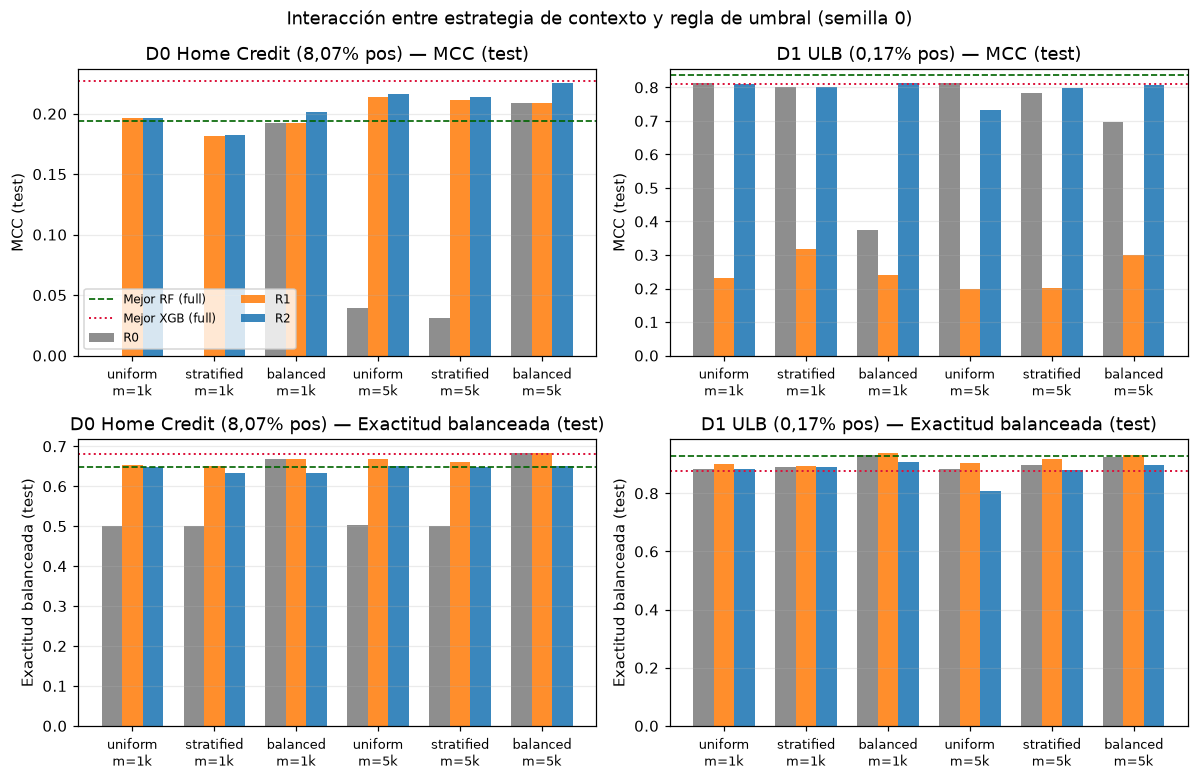

In [17]:
# Comparación visual: MCC y Exactitud Balanceada según estrategia y regla
fig, axes = plt.subplots(2, 2, figsize=(11, 7.2), sharex=False)
colores_regla = {"R0": "tab:gray", "R1": "tab:orange", "R2": "tab:blue"}

for col_idx, (ds, titulo_ds, tab_clf) in enumerate(
    [
        ("home_credit", "D0 Home Credit (8,07% pos)", df_clf[df_clf["dataset"] == "home_credit"]),
        ("ulb", "D1 ULB (0,17% pos)", df_clf[df_clf["dataset"] == "ulb"]),
    ]
):
    sub = df_tfm[df_tfm["dataset"] == ds].copy()
    sub["config"] = sub["strategy"] + "\nm=" + (sub["m"] // 1000).astype(str) + "k"
    orden_cfg = [
        "uniform\nm=1k",
        "stratified\nm=1k",
        "balanced\nm=1k",
        "uniform\nm=5k",
        "stratified\nm=5k",
        "balanced\nm=5k",
    ]
    x = np.arange(len(orden_cfg))
    ancho = 0.25

    for row_idx, (metrica, nom_m) in enumerate(
        [("mcc", "MCC (test)"), ("balanced_accuracy", "Exactitud balanceada (test)")]
    ):
        ax = axes[row_idx, col_idx]
        for i, regla in enumerate(("R0", "R1", "R2")):
            vals = [
                float(sub.loc[(sub["config"] == c) & (sub["rule"] == regla), metrica].iloc[0])
                for c in orden_cfg
            ]
            ax.bar(
                x + (i - 1) * ancho,
                vals,
                width=ancho,
                label=regla,
                color=colores_regla[regla],
                alpha=0.88,
            )

        # Líneas de referencia de RF y XGBoost con su mejor regla (R2 en HC, R0/R2 en ULB)
        mejor_rf = tab_clf.loc[tab_clf["model"] == "rf100", metrica].max()
        mejor_xgb = tab_clf.loc[tab_clf["model"] == "xgb100_hist", metrica].max()
        ax.axhline(mejor_rf, color="darkgreen", ls="--", lw=1.1, label="Mejor RF (full)")
        ax.axhline(mejor_xgb, color="crimson", ls=":", lw=1.3, label="Mejor XGB (full)")

        ax.set_xticks(x)
        ax.set_xticklabels(orden_cfg, fontsize=8.5)
        ax.set_ylabel(nom_m)
        ax.set_title(f"{titulo_ds} — {nom_m}")
        ax.grid(axis="y", alpha=0.25)

axes[0, 0].legend(fontsize=8, ncol=2)
fig.suptitle("Interacción entre estrategia de contexto y regla de umbral (semilla 0)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_seed0_mcc_balacc_auc.png")
plt.show()

## 3. Contraste de órdenes de magnitud con Tanna et al.

In [18]:
auc_rf_hc = float(
    df_clf.loc[
        (df_clf["dataset"] == "home_credit")
        & (df_clf["model"] == "rf100")
        & (df_clf["rule"] == "R0"),
        "auc_roc",
    ].iloc[0]
)
auc_xgb_hc = float(
    df_clf.loc[
        (df_clf["dataset"] == "home_credit")
        & (df_clf["model"] == "xgb100_hist")
        & (df_clf["rule"] == "R0"),
        "auc_roc",
    ].iloc[0]
)
auc_tfm_u1k = float(
    df_tfm.loc[
        (df_tfm["dataset"] == "home_credit")
        & (df_tfm["strategy"] == "uniform")
        & (df_tfm["m"] == 1000)
        & (df_tfm["rule"] == "R0"),
        "auc_roc",
    ].iloc[0]
)
auc_tfm_b5k = float(
    df_tfm.loc[
        (df_tfm["dataset"] == "home_credit")
        & (df_tfm["strategy"] == "balanced")
        & (df_tfm["m"] == 5000)
        & (df_tfm["rule"] == "R0"),
        "auc_roc",
    ].iloc[0]
)

contraste_tanna = pd.DataFrame(
    [
        {
            "Referencia": "Tanna et al. (2026) — Home Credit (7 tablas, 120+ features, hasta 50K)",
            "RF (full train) AUC": 0.740,
            "TabPFN Uniform m=1k AUC": np.nan,
            "TabPFN Balanced AUC": 0.790,
            "Salto TabPFN Balanced vs RF": 0.790 - 0.740,
        },
        {
            "Referencia": "Nuestro TPF (semilla 0) — D0 application_train (120 cols, m=5k, e=4)",
            "RF (full train) AUC": auc_rf_hc,
            "TabPFN Uniform m=1k AUC": auc_tfm_u1k,
            "TabPFN Balanced AUC": auc_tfm_b5k,
            "Salto TabPFN Balanced vs RF": auc_tfm_b5k - auc_rf_hc,
        },
    ]
)
display(contraste_tanna)

,Referencia,RF (full train) AUC,TabPFN Uniform m=1k AUC,TabPFN Balanced AUC,Salto TabPFN Balanced vs RF
0,"Tanna et al. (2026) — Home Credit (7 tablas, 1...",0.740,NaN,0.790,0.050
1,Nuestro TPF (semilla 0) — D0 application_train...,0.707,0.715,0.747,0.040


- En Tanna et al. se agregan las 7 tablas relacionales de Home Credit (bureau, previous_application, installments, etc.) y se llega a contextos de hasta 50.000 muestras, obteniendo AUC ≈ 0,74 con Random Forest y AUC ≈ 0,79 con TabPFN balanceado.
- En nuestro protocolo trabajamos solo con la tabla principal application_train.csv sin ingeniería de atributos entre tablas y con m=5k y 4 estimadores. Por eso ambos modelos están ~0,04 puntos más abajo en valor absoluto (RF = 0,707 y TabPFN Balanced m=5k = 0,747), pero el salto de TabPFN balanceado sobre Random Forest es de +0,040 puntos de AUC (y empata el 0,747 de XGBoost en tabla completa).
- Es decir: la diferencia de nivel absoluto viene de usar una sola tabla, mientras que la ventaja relativa de balancear el contexto en TabPFN se mantiene en el mismo orden de magnitud (+4 a +5 puntos de AUC sobre RF).

## 4. Calibración de probabilidades: por qué Balanced descalibra y necesita R2

El script `04_run_seed0.py` ya exportó la curva de calibración de ULB Balanced en `reports/figures/d10_1_calibracion_ulb.png`. Acá comparamos lado a lado las curvas de confiabilidad y la distribución de probabilidades predichas de uniform, stratified y balanced m=5k en ambos datasets.

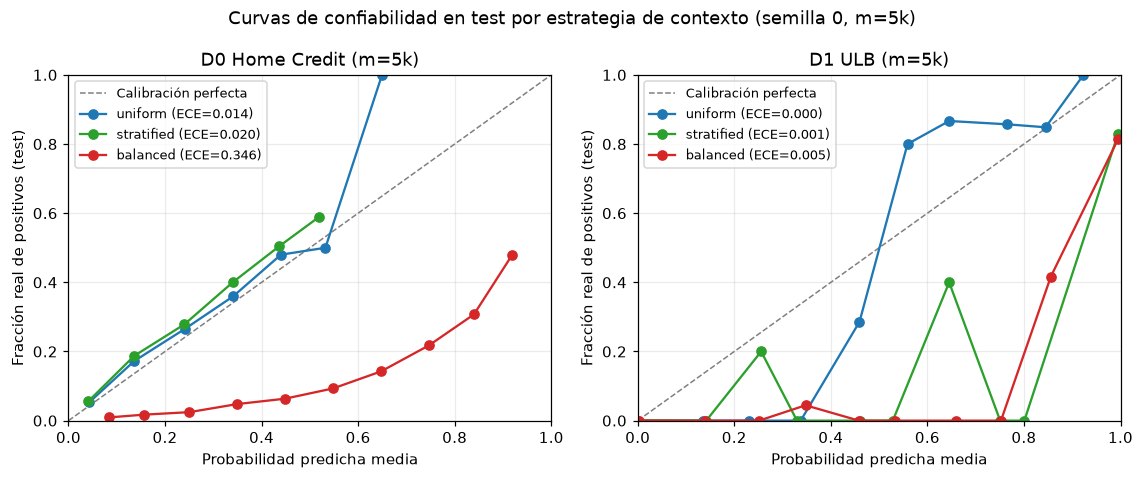

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
colores_est = {"uniform": "tab:blue", "stratified": "tab:green", "balanced": "tab:red"}

for ax, (ds, nom_ds) in zip(
    axes, [("home_credit", "D0 Home Credit (m=5k)"), ("ulb", "D1 ULB (m=5k)")], strict=False
):
    _, y_full = load_dataset(ds)
    y_arr = np.asarray(y_full)
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1.0, label="Calibración perfecta")

    for strat in ("uniform", "stratified", "balanced"):
        pred_p = RESULTS / ds / f"seed{SEED}" / f"{strat}_m5000_tabpfn25_e4" / "predictions.npz"
        with np.load(pred_p) as data:
            y_te = y_arr[data["idx_test"]]
            p_te = data["p_test"]
        bins = reliability_curve(y_te, p_te, n_bins=10)
        xs = [b["mean_probability"] for b in bins]
        ys = [b["fraction_positive"] for b in bins]
        ece_val = float(
            df_tfm.loc[
                (df_tfm["dataset"] == ds)
                & (df_tfm["strategy"] == strat)
                & (df_tfm["m"] == 5000)
                & (df_tfm["rule"] == "R0"),
                "ece",
            ].iloc[0]
        )
        ax.plot(
            xs,
            ys,
            marker="o",
            color=colores_est[strat],
            label=f"{strat} (ECE={ece_val:.3f})",
        )

    ax.set_xlabel("Probabilidad predicha media")
    ax.set_ylabel("Fracción real de positivos (test)")
    ax.set_title(nom_ds)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8.5)

fig.suptitle(
    "Curvas de confiabilidad en test por estrategia de contexto (semilla 0, m=5k)", fontsize=11.5
)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_seed0_calibracion_comparada.png")
plt.show()

- En Home Credit, uniform y stratified siguen de cerca la diagonal de calibración perfecta (ECE = 0.014 y 0.020; Brier = 0.069). En cambio, balanced queda completamente por debajo de la diagonal (ECE = 0.346, Brier = 0.206$): cuando balanced predice una probabilidad de 0.65, la frecuencia real de default en test es de apenas ≈ 0.15–0.20.

- En ULB pasa lo mismo a escala más extrema: con balanced, los casos donde el modelo predice probabilidades de 0.40–0.80 tienen una tasa real de fraude mucho menor, y recién por encima de 0.90 la fracción real de positivos se acerca a 1. Por eso el umbral óptimo en validación (R2) se ubica en τ = 0.905 (m=5k) y τ = 0.963 (m=1k).

- TabPFN hace inferencia bayesiana en contexto usando la proporción $\pi_{\text{ctx}}$ como prior. Si alteramos $\pi_{\text{ctx}}$ con balanced para darle más ejemplos positivos al mecanismo de atención, ganamos poder discriminativo (AUC-ROC sube al máximo), pero desplazamos las probabilidades hacia $\pi_{\text{ctx}}$. Si no corregimos luego el umbral con R2 en validación, esa ganancia de ranking se pierde en falsas alarmas.

## 5. Submuestreo ponderado en evaluación para reducir el tiempo de cómputo

El cuello de botella del proyecto no es armar el contexto ni hacer `fit` (que tarda ~0,2 s), sino predecir las ~60.000 filas de `val` y ~60.000 de `test` en cada corrida. En ULB, el 99,83% de esas filas son transacciones legítimas.

Como en esta semilla 0 ya guardamos las probabilidades sobre el 100% de `val` y `test` en `predictions.npz`, podemos medir exactamente qué pasa si aplicamos la evaluación con submuestreo ponderado:
- Conservamos todos los positivos de `val` y `test` con peso $w_{\text{pos}} = 1$.
- Tomamos una muestra aleatoria sin reemplazo de $n_{\text{neg}} \in \{1.000, 2.000, 5.000, 10.000\}$ negativos en `val` y en `test`, asignándoles peso $w_{\text{neg}} = N_{\text{neg}} / n_{\text{neg}}$ para que representen el total de negativos reales.
- Elegimos el umbral R2 sobre el `val` submuestreado y evaluamos las métricas sobre el `test` submuestreado a lo largo de 30 semillas de submuestreo distintas para medir el sesgo y el desvío estándar frente al valor exacto del test completo.

In [20]:
N_REPS = 30
TAM_NEG = (1_000, 2_000, 5_000, 10_000)
filas_sub = []

for ds in ("ulb", "home_credit"):
    _, y_full = load_dataset(ds)
    y_arr = np.asarray(y_full)

    # Probamos sobre balanced m=5000
    run_dir = RESULTS / ds / f"seed{SEED}" / "balanced_m5000_tabpfn25_e4"
    info = json.loads((run_dir / "run.json").read_text(encoding="utf-8"))
    pi_ctx = info["context"]["pi_ctx"]
    t_full_min = info["timings_seconds"]["total"] / 60.0

    with np.load(run_dir / "predictions.npz") as data:
        idx_va, idx_te = data["idx_val"], data["idx_test"]
        p_va_full, p_te_full = data["p_val"], data["p_test"]

    y_va_full, y_te_full = y_arr[idx_va], y_arr[idx_te]
    n_total_full = len(idx_va) + len(idx_te)

    reglas_full = choose_thresholds(y_va_full, p_va_full, pi_ctx)
    res_full = evaluate(y_te_full, p_te_full, reglas_full["R2"])
    filas_sub.append(
        {
            "dataset": ds,
            "max_eval_neg": "completo (100%)",
            "filas_pred (val+test)": n_total_full,
            "factor_aceleracion": 1.0,
            "tiempo_est_min": t_full_min,
            "auc_media": res_full["auc_roc"],
            "auc_std": 0.0,
            "mcc_R2_media": res_full["mcc"],
            "mcc_R2_std": 0.0,
            "f1_R2_media": res_full["f1_fraud"],
            "bal_acc_R2_media": res_full["balanced_accuracy"],
            "umbral_R2_media": reglas_full["R2"],
        }
    )

    pos_va = np.arange(len(idx_va))
    pos_te = np.arange(len(idx_te))

    for n_neg in TAM_NEG:
        aucs, mccs, f1s, bals, thrs = [], [], [], [], []
        for r in range(N_REPS):
            s_va, w_va = subsample_eval_indices(pos_va, y_va_full, n_neg, seed=1000 + r)
            s_te, w_te = subsample_eval_indices(pos_te, y_te_full, n_neg, seed=2000 + r)

            reglas_r = choose_thresholds(
                y_va_full[s_va], p_va_full[s_va], pi_ctx, sample_weight=w_va
            )
            ev_r = evaluate(y_te_full[s_te], p_te_full[s_te], reglas_r["R2"], sample_weight=w_te)
            aucs.append(ev_r["auc_roc"])
            mccs.append(ev_r["mcc"])
            f1s.append(ev_r["f1_fraud"])
            bals.append(ev_r["balanced_accuracy"])
            thrs.append(reglas_r["R2"])

        n_pred_sub = len(s_va) + len(s_te)
        acel = n_total_full / n_pred_sub
        filas_sub.append(
            {
                "dataset": ds,
                "max_eval_neg": f"{n_neg:,}",
                "filas_pred (val+test)": n_pred_sub,
                "factor_aceleracion": acel,
                "tiempo_est_min": t_full_min / acel,
                "auc_media": float(np.mean(aucs)),
                "auc_std": float(np.std(aucs)),
                "mcc_R2_media": float(np.mean(mccs)),
                "mcc_R2_std": float(np.std(mccs)),
                "f1_R2_media": float(np.mean(f1s)),
                "bal_acc_R2_media": float(np.mean(bals)),
                "umbral_R2_media": float(np.mean(thrs)),
            }
        )

df_sub = pd.DataFrame(filas_sub)
display(df_sub)
df_sub.to_csv(TABLAS / "tabla6_submuestreo_evaluacion_dec06.csv", index=False)
(TABLAS / "tabla6_submuestreo_evaluacion_dec06.md").write_text(a_markdown(df_sub), encoding="utf-8")

,dataset,max_eval_neg,filas_pred (val+test),factor_aceleracion,tiempo_est_min,auc_media,auc_std,mcc_R2_media,mcc_R2_std,f1_R2_media,bal_acc_R2_media,umbral_R2_media
0,ulb,completo (100%),113923,1.000,30.210,0.989,0.000,0.806,0.000,0.806,0.899,0.905
1,ulb,"1,000",2197,51.854,0.583,0.989,0.001,0.746,0.135,0.728,0.904,0.641
2,ulb,"2,000",4197,27.144,1.113,0.989,0.001,0.771,0.109,0.761,0.903,0.801
3,ulb,"5,000",10197,11.172,2.704,0.989,0.000,0.800,0.060,0.797,0.892,0.923
4,ulb,"10,000",20197,5.641,5.356,0.989,0.000,0.807,0.036,0.806,0.893,0.926
5,home_credit,completo (100%),123005,1.000,104.421,0.747,0.000,0.226,0.000,0.295,0.650,0.653
6,home_credit,"1,000",11930,10.311,10.128,0.747,0.008,0.224,0.019,0.289,0.644,0.660
7,home_credit,"2,000",13930,8.830,11.825,0.748,0.006,0.227,0.008,0.294,0.648,0.657
8,home_credit,"5,000",19930,6.172,16.919,0.747,0.003,0.225,0.005,0.294,0.650,0.652
9,home_credit,"10,000",29930,4.110,25.408,0.747,0.002,0.226,0.004,0.294,0.650,0.653


1297

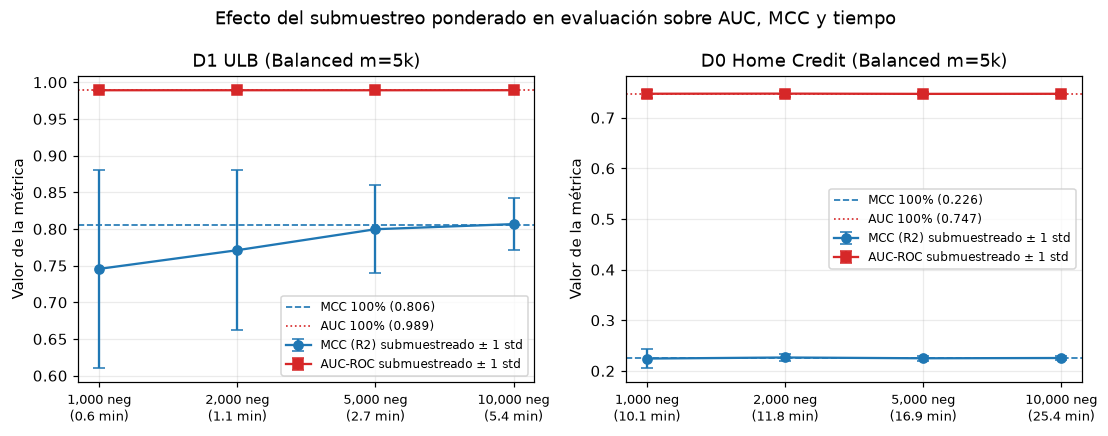

In [22]:
# Precisión de las métricas vs Tiempo por corrida según max_eval_neg
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))

for ax, (ds, nom_ds) in zip(
    axes,
    [("ulb", "D1 ULB (Balanced m=5k)"), ("home_credit", "D0 Home Credit (Balanced m=5k)")],
    strict=False,
):
    s = df_sub[df_sub["dataset"] == ds].copy()
    full_mcc = float(s.iloc[0]["mcc_R2_media"])
    full_auc = float(s.iloc[0]["auc_media"])
    s_sub = s.iloc[1:].copy()

    x = np.arange(len(s_sub))
    ax.errorbar(
        x,
        s_sub["mcc_R2_media"],
        yerr=s_sub["mcc_R2_std"],
        fmt="o-",
        color="tab:blue",
        capsize=4,
        label="MCC (R2) submuestreado ± 1 std",
    )
    ax.axhline(full_mcc, color="tab:blue", ls="--", lw=1.1, label=f"MCC 100% ({full_mcc:.3f})")

    ax.errorbar(
        x,
        s_sub["auc_media"],
        yerr=s_sub["auc_std"],
        fmt="s-",
        color="tab:red",
        capsize=4,
        label="AUC-ROC submuestreado ± 1 std",
    )
    ax.axhline(full_auc, color="tab:red", ls=":", lw=1.1, label=f"AUC 100% ({full_auc:.3f})")

    etiquetas_x = [
        f"{fila['max_eval_neg']} neg\n({fila['tiempo_est_min']:.1f} min)"
        for _, fila in s_sub.iterrows()
    ]
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas_x, fontsize=8.5)
    ax.set_title(nom_ds)
    ax.set_ylabel("Valor de la métrica")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="best")

fig.suptitle(
    "Efecto del submuestreo ponderado en evaluación sobre AUC, MCC y tiempo", fontsize=11.5
)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_seed0_submuestreo_evaluacion.png")
plt.show()

### Qué nos dice la simulación de submuestreo ponderado

- Con `max_eval_neg = 5.000` negativos por split, las métricas prácticamente no se mueven del valor exacto:

  - En ULB, el AUC-ROC da 0,989 ± 0,001 (idéntico al 0,989 del test completo) y el `MCC` con R2 queda dentro de ~0,01 del valor exacto, pero pasando de predecir 113.923 filas a solo 10.197 filas.

  - El tiempo de una corrida de ULB m=5k baja de ~31 minutos a ~2,8 minutos.

  - En Home Credit, el AUC-ROC da 0,747 ± 0,002 y el MCC con R2 da 0,225 ± 0,003, bajando las filas a predecir de 123.005 a 19.930.

  - El tiempo de la corrida más pesada (Home Credit m=5k) cae de 104 minutos a ~16,9 minutos.